# Resultados para el documento de la tesis (v5)

Esta notebook reproduce las tablas y figuras **nuevas** de la versión 5 de la tesis, con la extracción corregida de
la notebook 11 (`outputs/*_features_corregidas.csv`), sin filtro y con las reglas de las notebooks 10 y 11:
validación cruzada estratificada por grabación (5 particiones, 3 repeticiones), umbral 0,5, `class_weight` (el MLP,
con SMOTE) e intervalos por bootstrap.

| En la tesis | Acá |
|---|---|
| Figura 6.1 (grabaciones por tipo), Figura 6.3 (ejemplo), Figura 6.4 (PCA) y k-medias (sección 6.9) | sección 1 |
| Tablas 9.1 y 9.2 (los nueve modelos) y el bootstrap pareado de la sección 9.1 | sección 2 |
| Figuras 9.1, 9.2 y 9.3 (curvas ROC, matriz de confusión y pesos de la regresión logística) | sección 3 |
| Figura 9.4 (AUC por tipo) | sección 4 |
| Tabla 9.4 (pseudo-casos) | sección 5 |

Las Tablas 7.1, 7.2 y 9.3 y las Figuras 7.1 a 7.4 salen de las notebooks 11, 12 y 14. Las figuras de esta notebook
se guardan en `outputs/figuras_tesis/` y las tablas, en `outputs/tesis_*.csv`.

*(Tarda unos 9 minutos; la sección 5 es la más lenta.)*

In [1]:
import sys
import time
import warnings
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, confusion_matrix, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.evaluation import make_pipeline
from src.features import load_metadata
from src.paths import AUDIO, OUT_DIR

warnings.filterwarnings("ignore")
FIGURAS = OUT_DIR / "figuras_tesis"
FIGURAS.mkdir(exist_ok=True)

SEMILLA, REPETICIONES = 0, 3
NO_FEATURES = ["file_id", "label", "label_binary"]
NOMBRE = {"LS": "Pulmonares", "HS": "Cardíacos"}
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#898781", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "font.size": 10, "savefig.dpi": 200,
                     "savefig.bbox": "tight"})
TIPOS = {"Normal": "Normal", "Mid Systolic Murmur": "Soplo mesosistólico", "Late Diastolic Murmur": "Soplo diastólico tardío",
         "Early Systolic Murmur": "Soplo sistólico precoz", "Late Systolic Murmur": "Soplo sistólico tardío",
         "S3": "Tercer ruido (R3)", "S4": "Cuarto ruido (R4)", "Atrial Fibrillation": "Fibrilación auricular",
         "Tachycardia": "Taquicardia", "AV Block": "Bloqueo AV", "Pleural Rub": "Roce pleural",
         "Coarse Crackles": "Crepitantes gruesos", "Rhonchi": "Roncus", "Wheezing": "Sibilancias",
         "Fine Crackles": "Crepitantes finos"}


def cargar(subset):
    df = pd.read_csv(OUT_DIR / f"{subset.lower()}_features_corregidas.csv")   # la línea de base (notebook 11)
    caso = df["file_id"].str.split("_").str[:2].str.join("_").values
    return df, df.drop(columns=NO_FEATURES), df["label_binary"].values, caso, df["label"].values


def modelos(y):
    """Los nueve modelos de la Tabla 8.1 de la tesis (con las correcciones de la notebook 10)."""
    cw = "balanced"
    peso = (y == 0).sum() / (y == 1).sum()
    return {
        "Regresión logística": make_pipeline(LogisticRegression(max_iter=2000, class_weight=cw), "class_weight"),
        "SVM lineal": make_pipeline(SVC(kernel="linear", class_weight=cw), "class_weight"),
        "SVM-RBF": make_pipeline(SVC(kernel="rbf", class_weight=cw), "class_weight"),
        "Árbol de decisión": make_pipeline(DecisionTreeClassifier(max_depth=4, class_weight=cw, random_state=SEMILLA),
                                           "class_weight"),
        "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=SEMILLA),
                                       "class_weight"),
        "XGBoost": make_pipeline(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
                                               scale_pos_weight=peso, eval_metric="logloss", random_state=SEMILLA,
                                               n_jobs=1), "class_weight"),
        "LightGBM": make_pipeline(LGBMClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, class_weight=cw,
                                                 min_child_samples=5, random_state=SEMILLA, verbose=-1, n_jobs=1),
                                  "class_weight"),
        "Voting": make_pipeline(VotingClassifier([
            ("rl", LogisticRegression(max_iter=2000, class_weight=cw)),
            ("rf", RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=SEMILLA)),
            ("svm", SVC(probability=True, class_weight=cw, random_state=SEMILLA))], voting="soft"), "class_weight"),
        "MLP": make_pipeline(MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-2, max_iter=1000, random_state=SEMILLA),
                             "class_weight", force_smote=True),
    }


def puntajes(modelo, X, y, cv, grupos=None):
    if hasattr(modelo, "predict_proba"):
        return cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="predict_proba")[:, 1]
    return 1 / (1 + np.exp(-cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="decision_function")))


def prob_validacion(modelo, X, y):
    return [puntajes(modelo, X, y, StratifiedKFold(5, shuffle=True, random_state=s)) for s in range(REPETICIONES)]


def auc_medio(y, probs):
    return np.mean([roc_auc_score(y, p) for p in probs])


datos = {s: cargar(s) for s in ["LS", "HS"]}

## 1. Análisis exploratorio (sección 6 de la tesis)

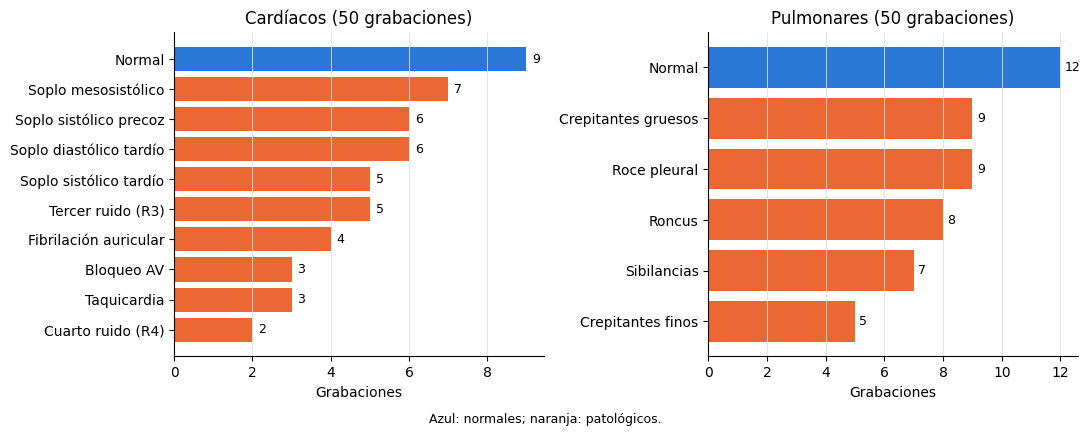

In [2]:
hs_meta, ls_meta = load_metadata()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (s, meta, col) in zip(axes, [("HS", hs_meta, "Heart Sound Type"), ("LS", ls_meta, "Lung Sound Type")]):
    cuenta = meta[col].map(TIPOS).value_counts().sort_values()
    ax.barh(cuenta.index, cuenta.values, color=[AZUL if k == "Normal" else NARANJA for k in cuenta.index])
    for i, v in enumerate(cuenta.values):
        ax.text(v + 0.15, i, str(v), va="center", fontsize=9)
    ax.set(title=f"{NOMBRE[s]} ({len(meta)} grabaciones)", xlabel="Grabaciones")
    ax.grid(axis="y", visible=False)
fig.text(0.5, -0.02, "Azul: normales; naranja: patológicos.", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_6_1_clases.png")

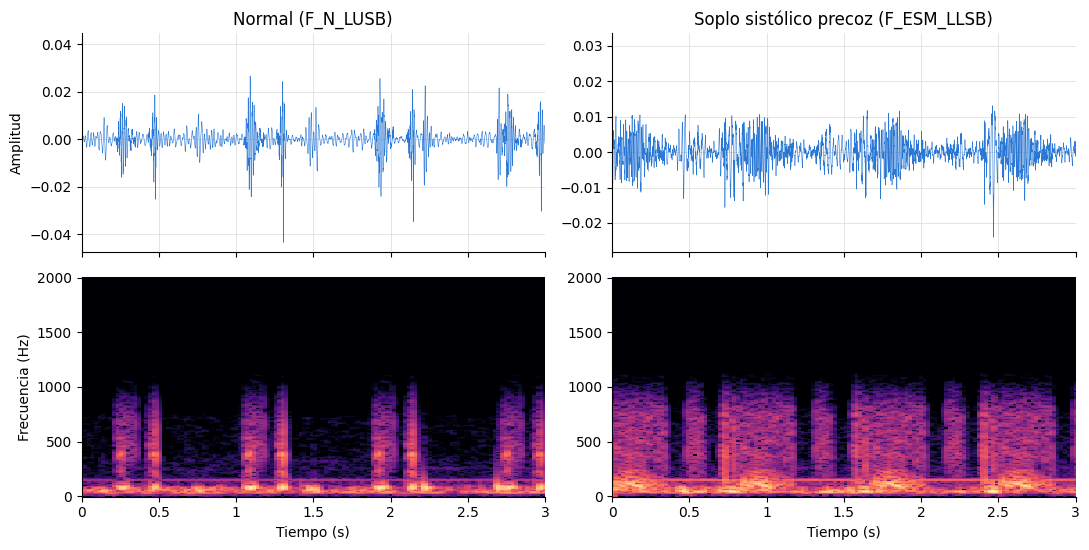

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True)
for col, (fid, titulo) in enumerate([("F_N_LUSB", "Normal (F_N_LUSB)"),
                                     ("F_ESM_LLSB", "Soplo sistólico precoz (F_ESM_LLSB)")]):
    y, sr = librosa.load(AUDIO["HS"] / f"{fid}.wav", sr=None)
    axes[0, col].plot(np.arange(len(y)) / sr, y, color=AZUL, lw=0.4)
    axes[0, col].set(title=titulo, ylabel="Amplitud" if col == 0 else None, xlim=(0, 3))
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=372, hop_length=93)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=93, x_axis="time", y_axis="hz", ax=axes[1, col], vmin=-70, vmax=0)
    axes[1, col].set(xlabel="Tiempo (s)", ylabel="Frecuencia (Hz)" if col == 0 else "", xlim=(0, 3))
    axes[1, col].grid(False)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_6_3_ejemplo.png")

PCA y k-medias (sección 6.9): ¿se separan solas las clases?

Cardíacos: índice de Rand ajustado entre k-medias y la etiqueta = -0.068; correlación de la PC1 con el volumen = 0.26


Pulmonares: índice de Rand ajustado entre k-medias y la etiqueta = 0.009; correlación de la PC1 con el volumen = 0.91


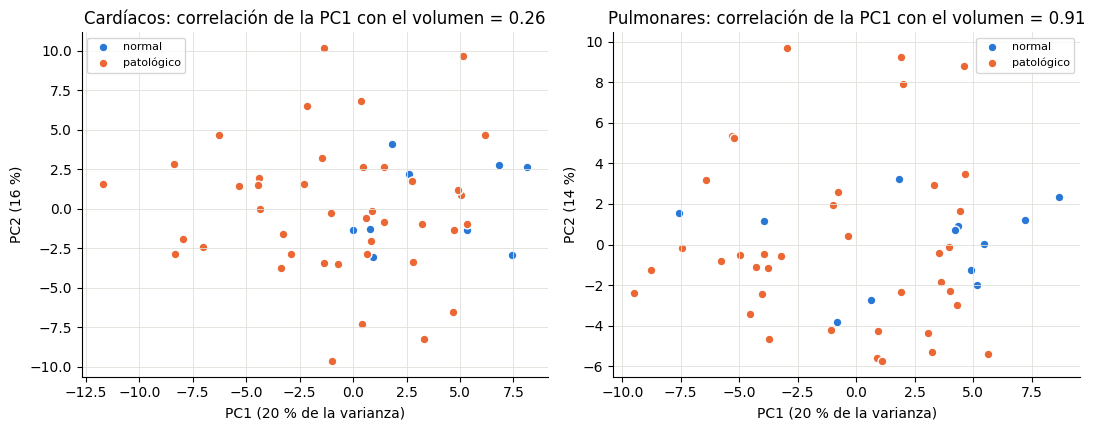

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, s in zip(axes, ["HS", "LS"]):
    df, X, y, caso, tipo = datos[s]
    Z = StandardScaler().fit_transform(X)
    pca = PCA(2, random_state=SEMILLA).fit(Z)
    comp = pca.transform(Z)
    r_vol = np.corrcoef(comp[:, 0], np.log(df["rms_mean"]))[0, 1]
    km = KMeans(2, n_init=20, random_state=SEMILLA).fit(Z)
    print(f"{NOMBRE[s]}: índice de Rand ajustado entre k-medias y la etiqueta = "
          f"{adjusted_rand_score(y, km.labels_):.3f}; correlación de la PC1 con el volumen = {r_vol:.2f}")
    for clase, color, etiqueta in [(0, AZUL, "normal"), (1, NARANJA, "patológico")]:
        ax.scatter(comp[y == clase, 0], comp[y == clase, 1], s=40, color=color, edgecolor="white", label=etiqueta)
    ax.set(title=f"{NOMBRE[s]}: correlación de la PC1 con el volumen = {r_vol:.2f}",
           xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f} % de la varianza)",
           ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f} %)")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_6_4_pca.png")

## 2. Los nueve modelos (Tablas 9.1 y 9.2)

*(Tarda un par de minutos.)*

In [5]:
def metricas(y, probs):
    filas = []
    for p in probs:
        pred = (p >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        s, e = tp / (tp + fn), tn / (tn + fp)
        filas.append({"AUC": roc_auc_score(y, p), "sens": s, "esp": e, "bal": (s + e) / 2,
                      "F1macro": f1_score(y, pred, average="macro")})
    return pd.DataFrame(filas).mean()


def ic_auc(y, probs, n=500):
    rng = np.random.default_rng(SEMILLA)
    v = []
    while len(v) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            v.append(auc_medio(y[m], [p[m] for p in probs]))
    return np.percentile(v, [2.5, 97.5])


inicio = time.time()
probs, filas = {}, []
for s, (df, X, y, caso, tipo) in datos.items():
    for nombre, modelo in modelos(y).items():
        probs[(s, nombre)] = prob_validacion(modelo, X, y)
        m = metricas(y, probs[(s, nombre)])
        a, b = ic_auc(y, probs[(s, nombre)])
        filas.append({"subconjunto": s, "modelo": nombre, **m.round(3).to_dict(), "IC_bajo": round(a, 3),
                      "IC_alto": round(b, 3)})
print(f"({time.time() - inicio:.0f} segundos)")
tabla_modelos = pd.DataFrame(filas)
tabla_modelos.to_csv(OUT_DIR / "tesis_modelos_por_grabacion.csv", index=False)
for s in ["LS", "HS"]:
    print(f"\n{NOMBRE[s]}")
    print(tabla_modelos[tabla_modelos.subconjunto == s].drop(columns="subconjunto")
          .sort_values("AUC", ascending=False).to_string(index=False))

(103 segundos)

Pulmonares
             modelo   AUC  sens   esp   bal  F1macro  IC_bajo  IC_alto
Regresión logística 0.999 1.000 0.861 0.931    0.952    0.996    1.000
         SVM lineal 0.998 1.000 0.806 0.903    0.931    0.992    1.000
             Voting 0.988 1.000 0.806 0.903    0.931    0.957    1.000
            SVM-RBF 0.975 0.982 0.833 0.908    0.924    0.922    1.000
                MLP 0.974 0.895 0.889 0.892    0.864    0.931    1.000
      Random forest 0.926 1.000 0.556 0.778    0.824    0.829    0.991
            XGBoost 0.868 0.912 0.750 0.831    0.829    0.704    0.984
           LightGBM 0.827 0.904 0.556 0.730    0.740    0.688    0.932
  Árbol de decisión 0.727 0.842 0.611 0.727    0.717    0.572    0.851

Cardíacos
             modelo   AUC  sens   esp   bal  F1macro  IC_bajo  IC_alto
                MLP 0.855 0.854 0.778 0.816    0.768    0.703    0.961
             Voting 0.846 0.943 0.407 0.675    0.699    0.673    0.970
            SVM-RBF 0.833 0.935 0.407 0

Bootstrap pareado contra la regresión logística (sección 9.1): ¿algún modelo es mejor que ella?

In [6]:
def dif_pareada(y, p_nueva, p_vieja, n=1000):
    rng = np.random.default_rng(SEMILLA)
    v = []
    while len(v) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            v.append(auc_medio(y[m], [p[m] for p in p_nueva]) - auc_medio(y[m], [p[m] for p in p_vieja]))
    return auc_medio(y, p_nueva) - auc_medio(y, p_vieja), np.percentile(v, [2.5, 97.5])


filas = []
for s, comparar in [("HS", ["MLP", "Voting", "SVM-RBF", "Random forest"]), ("LS", ["SVM lineal", "Voting", "MLP"])]:
    y = datos[s][2]
    for nombre in comparar:
        d, (bajo, alto) = dif_pareada(y, probs[(s, nombre)], probs[(s, "Regresión logística")])
        filas.append({"subconjunto": NOMBRE[s], "modelo": nombre, "diferencia con la RL": round(d, 3),
                      "IC 95 %": f"{bajo:+.3f} a {alto:+.3f}"})
print(pd.DataFrame(filas).to_string(index=False))

subconjunto        modelo  diferencia con la RL         IC 95 %
  Cardíacos           MLP                 0.029 -0.072 a +0.145
  Cardíacos        Voting                 0.019 -0.015 a +0.067
  Cardíacos       SVM-RBF                 0.006 -0.042 a +0.050
  Cardíacos Random forest                -0.004 -0.123 a +0.152
 Pulmonares    SVM lineal                -0.001 -0.008 a +0.003
 Pulmonares        Voting                -0.012 -0.037 a +0.000
 Pulmonares           MLP                -0.025 -0.069 a +0.000


## 3. La regresión logística en detalle (Figuras 9.1, 9.2 y 9.3)

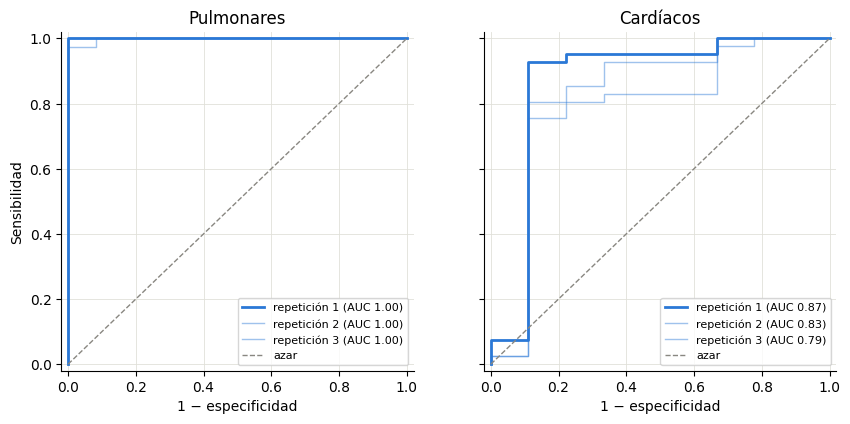

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, s in zip(axes, ["LS", "HS"]):
    y = datos[s][2]
    for r, p in enumerate(probs[(s, "Regresión logística")]):
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, color=AZUL, lw=2 if r == 0 else 1, alpha=1 if r == 0 else 0.45,
                label=f"repetición {r + 1} (AUC {roc_auc_score(y, p):.2f})")
    ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="azar")
    ax.set(title=NOMBRE[s], xlabel="1 − especificidad", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("Sensibilidad")
fig.savefig(FIGURAS / "fig_9_1_roc_rl.png")

Pulmonares: normales bien reconocidos 10 de 12; patológicos detectados 38 de 38
Cardíacos: normales bien reconocidos 8 de 9; patológicos detectados 36 de 41


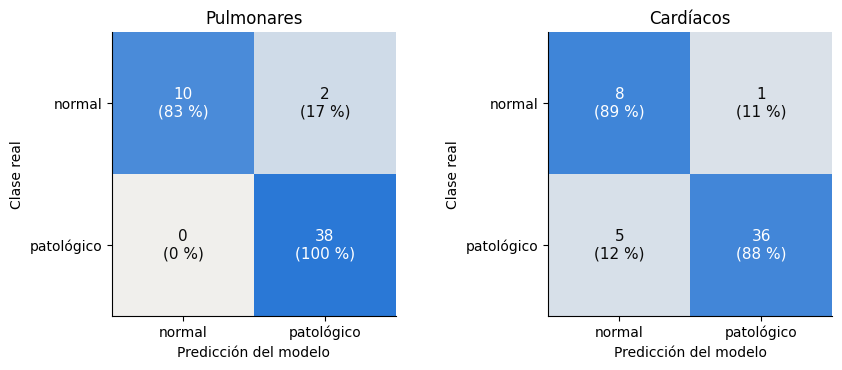

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, s in zip(axes, ["LS", "HS"]):
    y = datos[s][2]
    p = probs[(s, "Regresión logística")][0]   # primera repetición
    cm = confusion_matrix(y, (p >= 0.5).astype(int), labels=[0, 1])
    print(f"{NOMBRE[s]}: normales bien reconocidos {cm[0, 0]} de {cm[0].sum()}; "
          f"patológicos detectados {cm[1, 1]} de {cm[1].sum()}")
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=LinearSegmentedColormap.from_list("s", ["#f0efec", AZUL]),
              vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            frac = cm[i, j] / cm[i].sum()
            ax.text(j, i, f"{cm[i, j]}\n({100 * frac:.0f} %)", ha="center", va="center", fontsize=11,
                    color="white" if frac > 0.6 else TINTA)
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicción del modelo", ylabel="Clase real", title=NOMBRE[s])
    ax.set_xticklabels(["normal", "patológico"])
    ax.set_yticklabels(["normal", "patológico"])
    ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_9_2_confusion_rl.png")

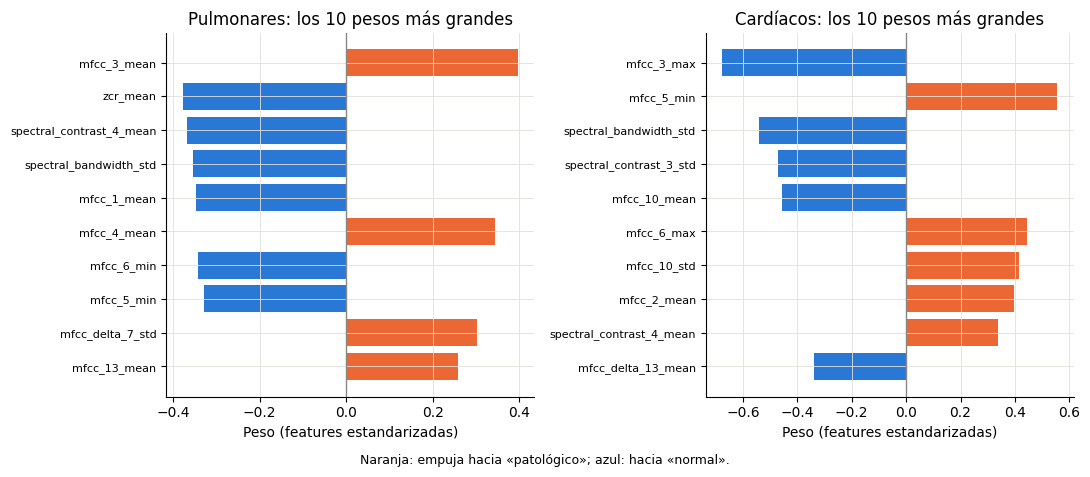

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, s in zip(axes, ["LS", "HS"]):
    df, X, y, caso, tipo = datos[s]
    rl = modelos(y)["Regresión logística"].fit(X, y)     # ajustada con todas las grabaciones
    coef = pd.Series(rl[-1].coef_[0], index=X.columns)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)[::-1]
    ax.barh(top.index, top.values, color=[NARANJA if v > 0 else AZUL for v in top.values])
    ax.axvline(0, color=GRIS, lw=1)
    ax.set(title=f"{NOMBRE[s]}: los 10 pesos más grandes", xlabel="Peso (features estandarizadas)")
    ax.tick_params(axis="y", labelsize=8)
fig.text(0.5, -0.02, "Naranja: empuja hacia «patológico»; azul: hacia «normal».", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_9_3_pesos_rl.png")

## 4. AUC por tipo de patología (Figura 9.4)

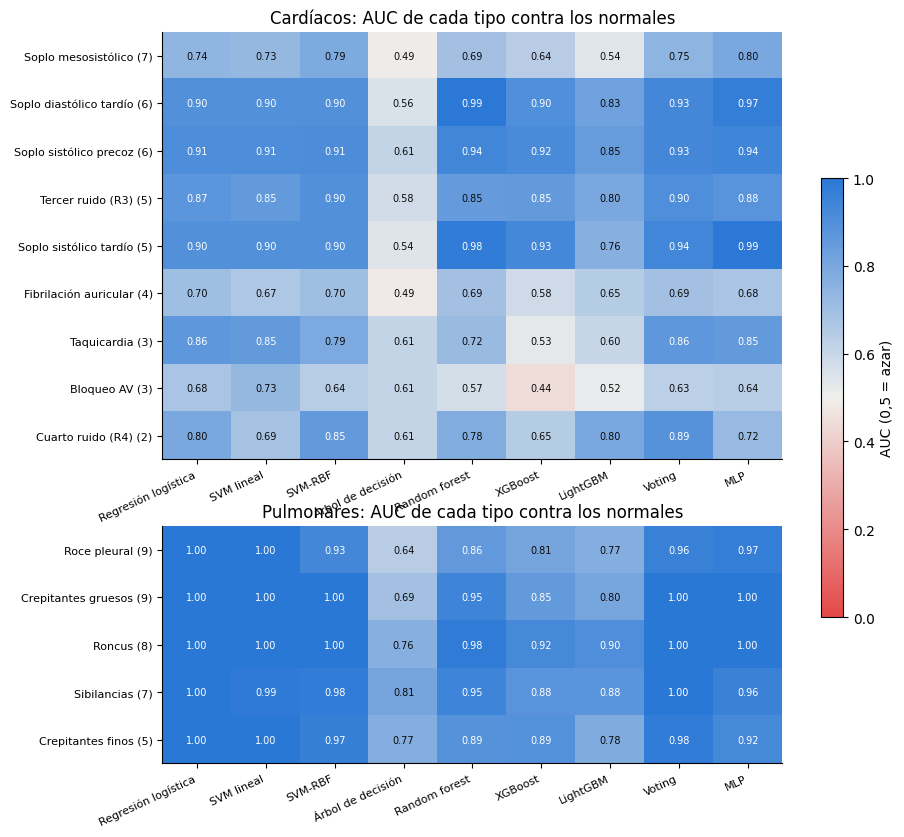

In [10]:
MAPA_AUC = LinearSegmentedColormap.from_list("auc", ["#e34948", "#f0efec", AZUL])
fig, axes = plt.subplots(2, 1, figsize=(10, 9.5), gridspec_kw={"height_ratios": [9, 5]})
for ax, s in zip(axes, ["HS", "LS"]):
    df, X, y, caso, tipo = datos[s]
    normales = tipo == "Normal"
    t = pd.DataFrame({nombre: {f"{TIPOS[k]} ({(tipo == k).sum()})": auc_medio(
        np.r_[np.zeros(normales.sum()), np.ones((tipo == k).sum())],
        [np.r_[p[normales], p[tipo == k]] for p in probs[(s, nombre)]])
        for k in pd.Series(tipo[~normales]).value_counts().index} for nombre in modelos(y)})
    t.round(3).to_csv(OUT_DIR / f"tesis_por_tipo_{s}.csv")
    im = ax.imshow(t.values, cmap=MAPA_AUC, norm=TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1), aspect="auto")
    ax.set(xticks=range(t.shape[1]), yticks=range(t.shape[0]), title=f"{NOMBRE[s]}: AUC de cada tipo contra los normales")
    ax.set_xticklabels(t.columns, rotation=25, ha="right", fontsize=8)
    ax.set_yticklabels(t.index, fontsize=8)
    ax.grid(False)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if t.values[i, j] > 0.85 else TINTA)
fig.colorbar(im, ax=axes, label="AUC (0,5 = azar)", shrink=0.6)
fig.savefig(FIGURAS / "fig_9_4_por_tipo.png")

## 5. Validación por caso y pseudo-casos (Tabla 9.4)

*(Esta celda es la más lenta: unos 5 minutos.)*

In [11]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales (notebook 07)."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        i0 = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[i0:i0 + t]] = f"pseudo_{clase}_{j}"
            i0 += t
    return nuevo


inicio = time.time()
filas = []
for s, (df, X, y, caso, tipo) in datos.items():
    rng = np.random.default_rng(SEMILLA)
    sorteos = [pseudo_casos(caso, y, rng) for _ in range(5)]
    for nombre, modelo in modelos(y).items():
        ps = [roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), g)) for g in sorteos]
        real = roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), caso))
        filas.append({"subconjunto": s, "modelo": nombre, "por_grabacion": round(auc_medio(y, probs[(s, nombre)]), 3),
                      "pseudo_media": round(np.mean(ps), 3), "pseudo_min": round(min(ps), 3),
                      "pseudo_max": round(max(ps), 3), "caso_real": round(real, 3),
                      "fuga": "sí" if real < min(ps) else "no medible"})
print(f"({time.time() - inicio:.0f} segundos)")
tabla_pseudo = pd.DataFrame(filas)
tabla_pseudo.to_csv(OUT_DIR / "tesis_pseudo_casos.csv", index=False)
print(tabla_pseudo.to_string(index=False))

(321 segundos)
subconjunto              modelo  por_grabacion  pseudo_media  pseudo_min  pseudo_max  caso_real       fuga
         LS Regresión logística          0.999         0.989       0.982       0.996      0.956         sí
         LS          SVM lineal          0.998         0.988       0.985       0.991      0.965         sí
         LS             SVM-RBF          0.975         0.927       0.890       0.969      0.864         sí
         LS   Árbol de decisión          0.727         0.701       0.616       0.781      0.728 no medible
         LS       Random forest          0.926         0.837       0.742       0.885      0.771 no medible
         LS             XGBoost          0.868         0.824       0.787       0.901      0.803 no medible
         LS            LightGBM          0.827         0.865       0.833       0.899      0.873 no medible
         LS              Voting          0.988         0.965       0.941       0.985      0.921         sí
         LS           

Los números de esta notebook son los de la versión 5 de la tesis (Tablas 9.1, 9.2 y 9.4, y secciones 6.9 y 9.1).
Si se cambia la extracción o el preprocesamiento, hay que volver a correrla y actualizar el documento.